In [1]:
import tqdm
import numpy as np
import quimb as qu
import pennylane as qml

from PhaseEstimation.utils import fidelity
from PhaseEstimation.annni.dmrg import dmrg_annni
from PhaseEstimation.annni.hamiltonian import get_energy_psi, get_H
from PhaseEstimation.utils.study.plot import imgs
from PhaseEstimation.mps.convert import mps_to_qc

/home/samonaco/Quantum-Phase-Detection-ANNNI/.venv/lib/python3.12/site-packages/cotengra/hyperoptimizers/hyper.py:36: UserWarning: Couldn't import `kahypar` - skipping from default hyper optimizer and using basic `labels` method instead.
  warnings.warn(


In [2]:
num_spins = 6
side = 6
depth = 3

ks, hs = np.linspace(0, 1, side), np.linspace(0, 2, side)
dev = qml.device("default.qubit", wires=num_spins)

In [3]:
E_brick, E_dmrg, E_true = np.zeros((side, side)), np.zeros((side, side)), np.zeros((side, side))
PSI_brick, PSI_dmrg, PSI_true = np.empty((side, side), dtype=object), np.empty((side, side), dtype=object), np.empty((side, side), dtype=object)
fid_truebrick, fid_truedmrg, fid_brickdmrg = np.zeros((side, side)), np.zeros((side, side)), np.zeros((side, side))

In [4]:
progress = tqdm.tqdm(range(len(ks) * len(hs)))
for x, k in enumerate(ks):
    for y, h in enumerate(hs):
        E_true[x, y], PSI_true[x, y] = get_energy_psi(num_spins, k, h)

        E_dmrg[x, y], mps_data = dmrg_annni(num_spins, 16, k, h) 
        mps = qu.tensor.tensor_1d.MatrixProductState(mps_data, shape="lpr")
        PSI_dmrg[x,y] = mps.to_dense()
        
        _, circuit_brick, _, _ = mps_to_qc(mps, depth = 6)
        
        @qml.qnode(dev)
        def circuit_psi():
            circuit_brick()
            return qml.state()

        H = get_H(num_spins, k, h, ring=False)
        @qml.qnode(dev)
        def circuit_E():
            circuit_brick()
            return qml.expval(H)

        PSI_brick[x, y] = circuit_psi()
        E_brick[x, y] = circuit_E()
        
        fid_truebrick[x, y] = fidelity(PSI_brick[x, y], PSI_true[x, y])
        fid_truedmrg[x, y] = fidelity(PSI_dmrg[x, y], PSI_true[x, y])
        fid_brickdmrg[x, y] = fidelity(PSI_dmrg[x, y], PSI_brick[x, y])
        
        progress.update(1)

100%|██████████| 36/36 [02:37<00:00,  4.42s/it]

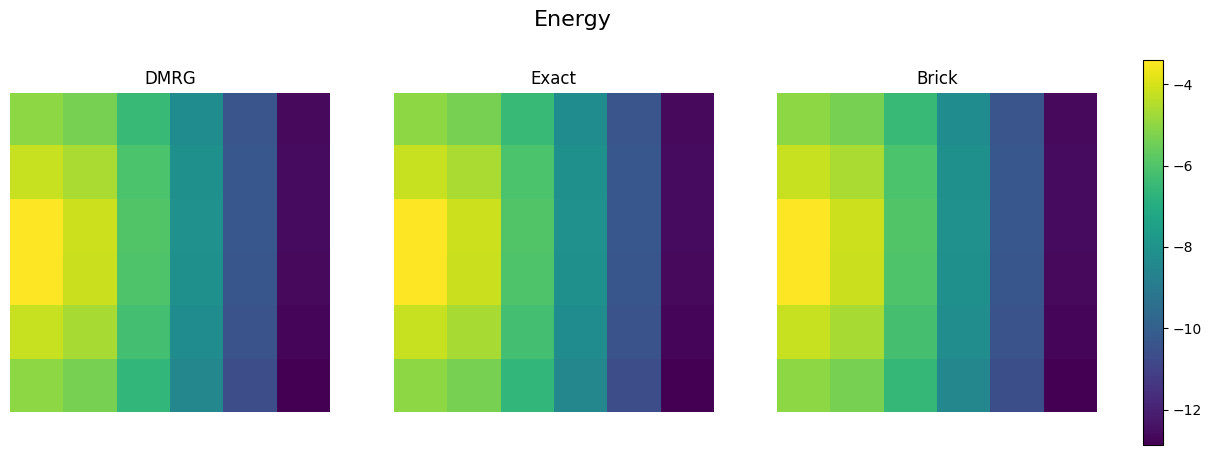

In [16]:
imgs([E_dmrg, E_true, E_brick], ["DMRG", "Exact", "Brick"], "Energy", cmap="viridis")

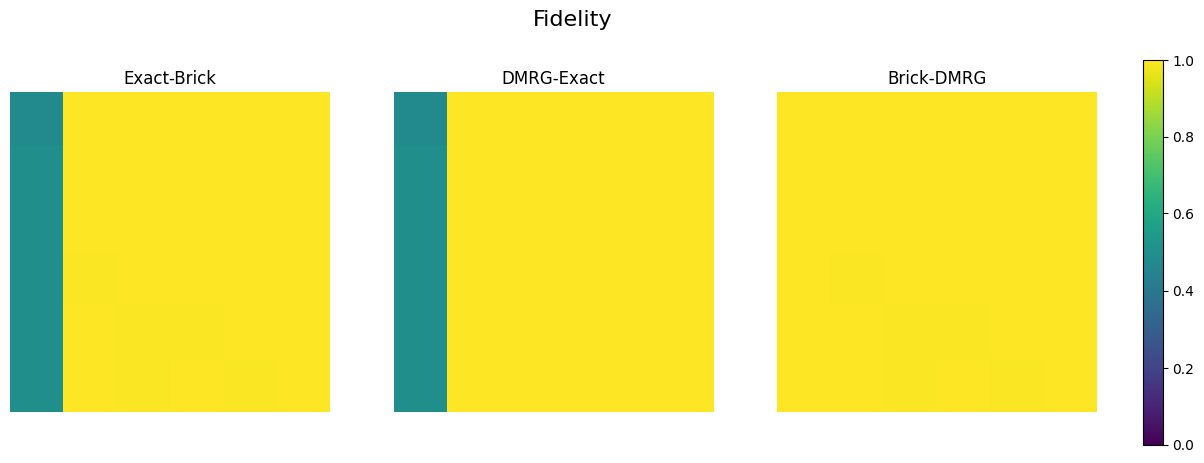

In [17]:
imgs([fid_truebrick, fid_truedmrg, fid_brickdmrg], ["Exact-Brick", "DMRG-Exact", "Brick-DMRG"], "Fidelity", cmap="viridis", _range=(0, 1))
